In [7]:
from google.colab import files

uploaded = files.upload()

KeyboardInterrupt: 

In [8]:
import pandas as pd

df = pd.read_csv("/content/diabetes_data_upload.csv")

df.head()

,Age,Gender,Polyuria,Polydipsia,sudden weight loss,weakness,Polyphagia,Genital thrush,visual blurring,Itching,Irritability,delayed healing,partial paresis,muscle stiffness,Alopecia,Obesity,class
0,40,Male,No,Yes,No,Yes,No,No,No,Yes,No,Yes,No,Yes,Yes,Yes,Positive
1,58,Male,No,No,No,Yes,No,No,Yes,No,No,No,Yes,No,Yes,No,Positive
2,41,Male,Yes,No,No,Yes,Yes,No,No,Yes,No,Yes,No,Yes,Yes,No,Positive
3,45,Male,No,No,Yes,Yes,Yes,Yes,No,Yes,No,Yes,No,No,No,No,Positive
4,60,Male,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Positive


In [9]:
df.shape
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 520 entries, 0 to 519
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Age                 520 non-null    int64 
 1   Gender              520 non-null    object
 2   Polyuria            520 non-null    object
 3   Polydipsia          520 non-null    object
 4   sudden weight loss  520 non-null    object
 5   weakness            520 non-null    object
 6   Polyphagia          520 non-null    object
 7   Genital thrush      520 non-null    object
 8   visual blurring     520 non-null    object
 9   Itching             520 non-null    object
 10  Irritability        520 non-null    object
 11  delayed healing     520 non-null    object
 12  partial paresis     520 non-null    object
 13  muscle stiffness    520 non-null    object
 14  Alopecia            520 non-null    object
 15  Obesity             520 non-null    object
 16  class               520 no

In [10]:
df.duplicated().sum()

np.int64(269)

In [11]:
df.isnull().sum()

,0
Age,0
Gender,0
Polyuria,0
Polydipsia,0
sudden weight loss,0
weakness,0
Polyphagia,0
Genital thrush,0
visual blurring,0
Itching,0


In [12]:
df[df.duplicated(keep=False)].sort_values(by=df.columns.tolist()).head(20)

,Age,Gender,Polyuria,Polydipsia,sudden weight loss,weakness,Polyphagia,Genital thrush,visual blurring,Itching,Irritability,delayed healing,partial paresis,muscle stiffness,Alopecia,Obesity,class
219,27,Male,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Negative
277,27,Male,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Negative
286,27,Male,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Negative
374,27,Male,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Negative
465,27,Male,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Negative
474,27,Male,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Negative
87,28,Female,No,No,No,No,No,No,Yes,No,No,No,Yes,Yes,No,No,Positive
160,28,Female,No,No,No,No,No,No,Yes,No,No,No,Yes,Yes,No,No,Positive
265,28,Female,No,No,No,No,No,No,Yes,No,No,No,Yes,Yes,No,No,Positive
362,28,Female,No,No,No,No,No,No,Yes,No,No,No,Yes,Yes,No,No,Positive


In [13]:
df = df.drop_duplicates().reset_index(drop=True)

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (251, 17)


In [14]:
df["class"].value_counts()

,count
class,
Positive,173
Negative,78


In [15]:
for col in df.columns:
    print(f"\n{col}:")
    print(df[col].unique())


Age:
[40 58 41 45 60 55 57 66 67 70 44 38 35 61 54 43 62 39 48 32 42 52 53 37
 49 63 30 50 46 36 51 59 65 25 47 28 68 56 31 85 90 72 69 79 34 16 33 64
 27 29 26]

Gender:
['Male' 'Female']

Polyuria:
['No' 'Yes']

Polydipsia:
['Yes' 'No']

sudden weight loss:
['No' 'Yes']

weakness:
['Yes' 'No']

Polyphagia:
['No' 'Yes']

Genital thrush:
['No' 'Yes']

visual blurring:
['No' 'Yes']

Itching:
['Yes' 'No']

Irritability:
['No' 'Yes']

delayed healing:
['Yes' 'No']

partial paresis:
['No' 'Yes']

muscle stiffness:
['Yes' 'No']

Alopecia:
['Yes' 'No']

Obesity:
['Yes' 'No']

class:
['Positive' 'Negative']


In [16]:
X = df.drop("class", axis=1)
y = df["class"]

print("Features:", X.shape)
print("Target:", y.shape)


Features: (251, 16)
Target: (251,)


In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (200, 16)
X_test: (51, 16)
y_train: (200,)
y_test: (51,)


In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Numerical column
numerical_columns = ["Age"]

# Categorical columns
categorical_columns = [col for col in X.columns if col != "Age"]

# Preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_columns)
    ],
    remainder="passthrough"
)

preprocessor

ColumnTransformer(remainder='passthrough',
                  transformers=[('cat', OneHotEncoder(handle_unknown='ignore'),
                                 ['Gender', 'Polyuria', 'Polydipsia',
                                  'sudden weight loss', 'weakness',
                                  'Polyphagia', 'Genital thrush',
                                  'visual blurring', 'Itching', 'Irritability',
                                  'delayed healing', 'partial paresis',
                                  'muscle stiffness', 'Alopecia', 'Obesity'])])

In [19]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("X_train processed shape:", X_train_processed.shape)
print("X_test processed shape:", X_test_processed.shape)

X_train processed shape: (200, 31)
X_test processed shape: (51, 31)


In [21]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

model = LogisticRegression(max_iter=1000, random_state=42)

model.fit(X_train_processed, y_train)

y_pred = model.predict(X_test_processed)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.803921568627451

Classification Report:
              precision    recall  f1-score   support

    Negative       0.64      0.88      0.74        16
    Positive       0.93      0.77      0.84        35

    accuracy                           0.80        51
   macro avg       0.78      0.82      0.79        51
weighted avg       0.84      0.80      0.81        51



[[14  2]
 [ 8 27]]


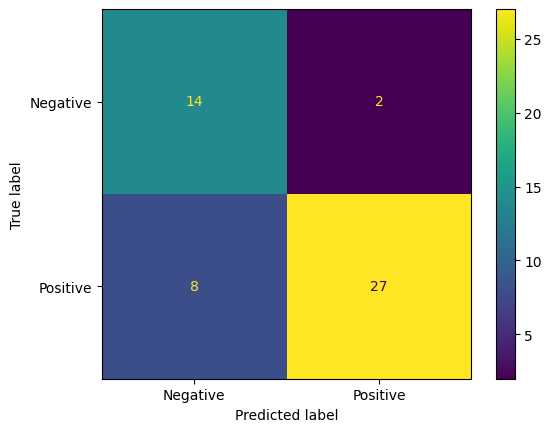

In [22]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

disp.plot()
plt.show()

In [24]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train_processed, y_train)

rf_pred = rf_model.predict(X_test_processed)

print("Random Forest Accuracy:", accuracy_score(y_test, rf_pred))
print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

Random Forest Accuracy: 0.9019607843137255

Classification Report:
              precision    recall  f1-score   support

    Negative       0.79      0.94      0.86        16
    Positive       0.97      0.89      0.93        35

    accuracy                           0.90        51
   macro avg       0.88      0.91      0.89        51
weighted avg       0.91      0.90      0.90        51



[[15  1]
 [ 4 31]]


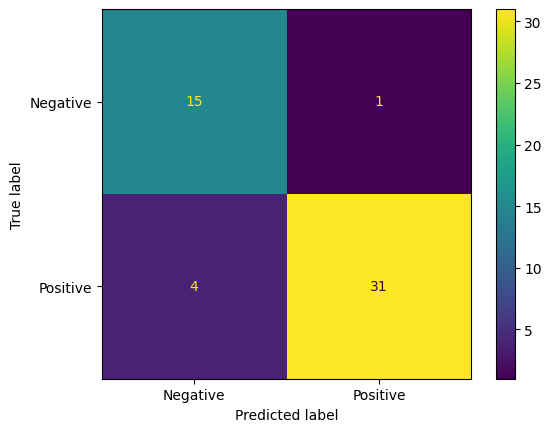

In [25]:
cm_rf = confusion_matrix(y_test, rf_pred)

print(cm_rf)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["Negative", "Positive"]
)

disp.plot()
plt.show()

In [26]:
from sklearn.svm import SVC

svm_model = SVC(
    kernel="rbf",
    probability=True,
    random_state=42
)

svm_model.fit(X_train_processed, y_train)

svm_pred = svm_model.predict(X_test_processed)

print("SVM Accuracy:", accuracy_score(y_test, svm_pred))
print("\nClassification Report:")
print(classification_report(y_test, svm_pred))

SVM Accuracy: 0.6862745098039216

Classification Report:
              precision    recall  f1-score   support

    Negative       0.00      0.00      0.00        16
    Positive       0.69      1.00      0.81        35

    accuracy                           0.69        51
   macro avg       0.34      0.50      0.41        51
weighted avg       0.47      0.69      0.56        51



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [27]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor_svm = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), ["Age"]),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_columns)
    ]
)

X_train_svm = preprocessor_svm.fit_transform(X_train)
X_test_svm = preprocessor_svm.transform(X_test)

In [28]:
svm_model_scaled = SVC(
    kernel="rbf",
    probability=True,
    random_state=42
)

svm_model_scaled.fit(X_train_svm, y_train)

svm_pred_scaled = svm_model_scaled.predict(X_test_svm)

print("SVM Accuracy:", accuracy_score(y_test, svm_pred_scaled))
print("\nClassification Report:")
print(classification_report(y_test, svm_pred_scaled))

SVM Accuracy: 0.9215686274509803

Classification Report:
              precision    recall  f1-score   support

    Negative       0.83      0.94      0.88        16
    Positive       0.97      0.91      0.94        35

    accuracy                           0.92        51
   macro avg       0.90      0.93      0.91        51
weighted avg       0.93      0.92      0.92        51



In [29]:
y_train_xgb = y_train.map({"Negative": 0, "Positive": 1})
y_test_xgb = y_test.map({"Negative": 0, "Positive": 1})

In [30]:
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.1,
    random_state=42,
    eval_metric="logloss"
)

xgb_model.fit(X_train_processed, y_train_xgb)

xgb_pred = xgb_model.predict(X_test_processed)

print("XGBoost Accuracy:", accuracy_score(y_test_xgb, xgb_pred))
print("\nClassification Report:")
print(
    classification_report(
        y_test_xgb,
        xgb_pred,
        target_names=["Negative", "Positive"]
    )
)

NameError: name 'XGBClassifier' is not defined

In [31]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.svm import SVC

# Preprocessing + SVM pipeline
svm_pipeline = Pipeline([
    ("preprocessor", preprocessor_svm),
    ("model", SVC(
        kernel="rbf",
        probability=True,
        random_state=42
    ))
])

# 5-Fold Stratified CV
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = cross_validate(
    svm_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=[
        "accuracy",
        "precision",
        "recall",
        "f1",
        "roc_auc"
    ]
)

print("CV Accuracy:", cv_results["test_accuracy"])
print("Mean Accuracy:", cv_results["test_accuracy"].mean())

print("\nMean Precision:", cv_results["test_precision"].mean())
print("Mean Recall:", cv_results["test_recall"].mean())
print("Mean F1:", cv_results["test_f1"].mean())
print("Mean ROC-AUC:", cv_results["test_roc_auc"].mean())

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py:978: UserWarning: Scoring failed. The score on this train-test partition for these parameters will be set to nan. Details: 
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_scorer.py", line 140, in __call__
    score = scorer._score(
        cached_call, estimator, *args, **routed_params.get(name).score
    )
  File "/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_scorer.py", line 388, in _score
    return self._sign * self._score_func(y_true, y_pred, **scoring_kwargs)
                        ~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/sklearn/utils/_param_validation.py", line 216, in wrapper
    return func(*args, **kwargs)
  File "/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py", line 2247, in precision_score
    p, _, _, _ = precision_recall_fscore_support(
        

CV Accuracy: [0.925 1.    0.9   0.975 0.925]
Mean Accuracy: 0.9450000000000001

Mean Precision: nan
Mean Recall: nan
Mean F1: nan
Mean ROC-AUC: 0.9812576312576313


/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py:978: UserWarning: Scoring failed. The score on this train-test partition for these parameters will be set to nan. Details: 
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_scorer.py", line 140, in __call__
    score = scorer._score(
        cached_call, estimator, *args, **routed_params.get(name).score
    )
  File "/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_scorer.py", line 388, in _score
    return self._sign * self._score_func(y_true, y_pred, **scoring_kwargs)
                        ~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/sklearn/utils/_param_validation.py", line 216, in wrapper
    return func(*args, **kwargs)
  File "/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py", line 2247, in precision_score
    p, _, _, _ = precision_recall_fscore_support(
        

In [32]:
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score

scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(
        precision_score,
        pos_label="Positive"
    ),
    "recall": make_scorer(
        recall_score,
        pos_label="Positive"
    ),
    "f1": make_scorer(
        f1_score,
        pos_label="Positive"
    ),
    "roc_auc": "roc_auc"
}

cv_results = cross_validate(
    svm_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

print("CV Accuracy:", cv_results["test_accuracy"])
print("Mean Accuracy:", cv_results["test_accuracy"].mean())

print("\nMean Precision:", cv_results["test_precision"].mean())
print("Mean Recall:", cv_results["test_recall"].mean())
print("Mean F1:", cv_results["test_f1"].mean())
print("Mean ROC-AUC:", cv_results["test_roc_auc"].mean())

CV Accuracy: [0.925 1.    0.9   0.975 0.925]
Mean Accuracy: 0.9450000000000001

Mean Precision: 0.9571246122970262
Mean Recall: 0.9640211640211641
Mean F1: 0.9603873319662795
Mean ROC-AUC: 0.9812576312576313


In [33]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

models = {
    "Logistic Regression": Pipeline([
        ("preprocessor", preprocessor_svm),
        ("model", LogisticRegression(max_iter=1000, random_state=42))
    ]),

    "Random Forest": Pipeline([
        ("preprocessor", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=100,
            random_state=42
        ))
    ]),

    "SVM": Pipeline([
        ("preprocessor", preprocessor_svm),
        ("model", SVC(
            kernel="rbf",
            probability=True,
            random_state=42
        ))
    ]),

    "XGBoost": Pipeline([
        ("preprocessor", preprocessor),
        ("model", XGBClassifier(
            n_estimators=100,
            max_depth=3,
            learning_rate=0.1,
            random_state=42,
            eval_metric="logloss"
        ))
    ])
}

In [34]:
y_train_encoded = y_train.map({
    "Negative": 0,
    "Positive": 1
})

In [35]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(
        precision_score,
        pos_label="Positive"
    ),
    "recall": make_scorer(
        recall_score,
        pos_label="Positive"
    ),
    "f1": make_scorer(
        f1_score,
        pos_label="Positive"
    ),
    "roc_auc": "roc_auc"
}

cv_summary = {}

for name, pipeline in models.items():

    if name == "XGBoost":
        results = cross_validate(
            pipeline,
            X_train,
            y_train_encoded,
            cv=cv,
            scoring={
                "accuracy": "accuracy",
                "precision": make_scorer(
                    precision_score,
                    pos_label=1
                ),
                "recall": make_scorer(
                    recall_score,
                    pos_label=1
                ),
                "f1": make_scorer(
                    f1_score,
                    pos_label=1
                ),
                "roc_auc": "roc_auc"
            }
        )
    else:
        results = cross_validate(
            pipeline,
            X_train,
            y_train,
            cv=cv,
            scoring=scoring
        )

    cv_summary[name] = {
        "Accuracy": results["test_accuracy"].mean(),
        "Precision": results["test_precision"].mean(),
        "Recall": results["test_recall"].mean(),
        "F1": results["test_f1"].mean(),
        "ROC-AUC": results["test_roc_auc"].mean()
    }

cv_comparison = pd.DataFrame(cv_summary).T

print(cv_comparison)

                     Accuracy  Precision    Recall        F1   ROC-AUC
Logistic Regression     0.885   0.927524  0.905556  0.914889  0.968620
Random Forest           0.940   0.957546  0.956614  0.956463  0.977167
SVM                     0.945   0.957125  0.964021  0.960387  0.981258
XGBoost                 0.925   0.949371  0.942328  0.945146  0.975560


In [36]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer, f1_score

f1_scorer = make_scorer(
    f1_score,
    pos_label="Positive"
)

param_grid = {
    "model__C": [0.1, 1, 10, 100],
    "model__gamma": ["scale", 0.01, 0.1, 1]
}

grid_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring=f1_scorer,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest CV F1-score:")
print(grid_search.best_score_)

Best Parameters:
{'model__C': 1, 'model__gamma': 'scale'}

Best CV F1-score:
0.9603873319662795


In [37]:
best_svm = grid_search.best_estimator_

print(best_svm)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Age']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Gender', 'Polyuria',
                                                   'Polydipsia',
                                                   'sudden weight loss',
                                                   'weakness', 'Polyphagia',
                                                   'Genital thrush',
                                                   'visual blurring', 'Itching',
                                                   'Irritability',
                                                   'delayed healing',
                                                   'partial paresis',
                                        

In [38]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

y_test_pred = best_svm.predict(X_test)

y_test_proba = best_svm.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_test_pred))
print("Precision:", precision_score(
    y_test, y_test_pred, pos_label="Positive"
))
print("Recall:", recall_score(
    y_test, y_test_pred, pos_label="Positive"
))
print("F1-score:", f1_score(
    y_test, y_test_pred, pos_label="Positive"
))
print("ROC-AUC:", roc_auc_score(
    y_test.map({"Negative": 0, "Positive": 1}),
    y_test_proba
))

print("\nClassification Report:\n")
print(classification_report(y_test, y_test_pred))

Accuracy: 0.9215686274509803
Precision: 0.9696969696969697
Recall: 0.9142857142857143
F1-score: 0.9411764705882353
ROC-AUC: 0.9660714285714286

Classification Report:

              precision    recall  f1-score   support

    Negative       0.83      0.94      0.88        16
    Positive       0.97      0.91      0.94        35

    accuracy                           0.92        51
   macro avg       0.90      0.93      0.91        51
weighted avg       0.93      0.92      0.92        51



[[15  1]
 [ 3 32]]


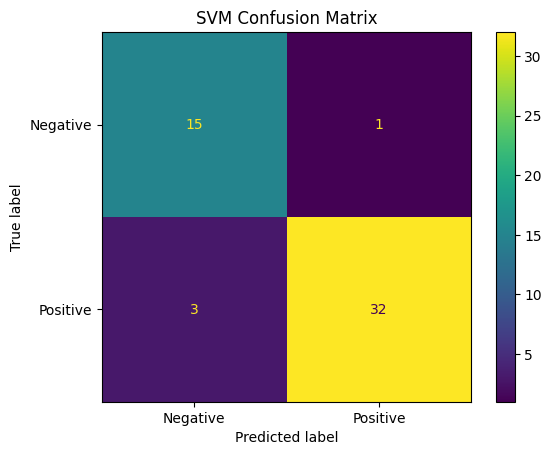

In [39]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=["Negative", "Positive"]
)

print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

disp.plot()
plt.title("SVM Confusion Matrix")
plt.show()

In [40]:
error_df = X_test.copy()

error_df["Actual"] = y_test
error_df["Predicted"] = y_test_pred

errors = error_df[
    error_df["Actual"] != error_df["Predicted"]
]

print("Number of errors:", len(errors))
print(errors)

Number of errors: 4
     Age  Gender Polyuria Polydipsia sudden weight loss weakness Polyphagia  \
88    35  Female       No         No                 No       No         No   
32    37    Male       No         No                 No      Yes         No   
154   33    Male       No        Yes                 No       No         No   
226   47    Male       No         No                 No       No         No   

    Genital thrush visual blurring Itching Irritability delayed healing  \
88              No              No      No           No              No   
32              No              No      No           No             Yes   
154             No              No      No           No              No   
226             No              No      No          Yes              No   

    partial paresis muscle stiffness Alopecia Obesity    Actual Predicted  
88               No               No       No      No  Positive  Negative  
32               No               No      Yes      No  P

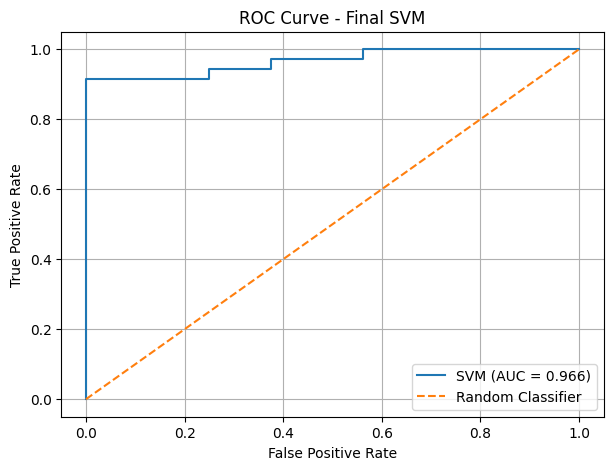

In [45]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Positive class probability
y_test_binary = y_test.map({
    "Negative": 0,
    "Positive": 1
})

fpr, tpr, thresholds = roc_curve(
    y_test_binary,
    y_test_proba
)

auc_score = roc_auc_score(
    y_test_binary,
    y_test_proba
)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"SVM (AUC = {auc_score:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Final SVM")
plt.legend()
plt.grid()
plt.show()

In [42]:
y_test_binary = y_test.map({
    "Negative": 0,
    "Positive": 1
})

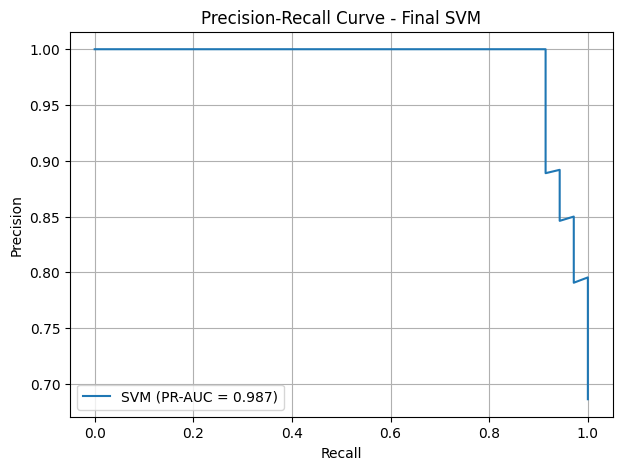

PR-AUC: 0.9867813267813267


In [44]:
from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

precision, recall, thresholds = precision_recall_curve(
    y_test_binary,
    y_test_proba
)

pr_auc = average_precision_score(
    y_test_binary,
    y_test_proba
)

plt.figure(figsize=(7, 5))

plt.plot(
    recall,
    precision,
    label=f"SVM (PR-AUC = {pr_auc:.3f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Final SVM")
plt.legend()
plt.grid()
plt.show()

print("PR-AUC:", pr_auc)

In [46]:
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds_to_test = [0.30, 0.40, 0.50, 0.60, 0.70]

threshold_results = []

for threshold in thresholds_to_test:

    y_pred_threshold = np.where(
        y_test_proba >= threshold,
        "Positive",
        "Negative"
    )

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test,
            y_pred_threshold,
            pos_label="Positive"
        ),
        "Recall": recall_score(
            y_test,
            y_pred_threshold,
            pos_label="Positive"
        ),
        "F1": f1_score(
            y_test,
            y_pred_threshold,
            pos_label="Positive"
        )
    })

threshold_df = pd.DataFrame(threshold_results)

print(threshold_df)

   Threshold  Precision    Recall        F1
0        0.3   0.891892  0.942857  0.916667
1        0.4   0.941176  0.914286  0.927536
2        0.5   0.969697  0.914286  0.941176
3        0.6   1.000000  0.828571  0.906250
4        0.7   1.000000  0.771429  0.870968


In [47]:
final_model_comparison = cv_comparison.copy()

final_model_comparison = final_model_comparison.round(4)

print(final_model_comparison)

                     Accuracy  Precision  Recall      F1  ROC-AUC
Logistic Regression     0.885     0.9275  0.9056  0.9149   0.9686
Random Forest           0.940     0.9575  0.9566  0.9565   0.9772
SVM                     0.945     0.9571  0.9640  0.9604   0.9813
XGBoost                 0.925     0.9494  0.9423  0.9451   0.9756


In [48]:
final_model_comparison_percentage = (
    final_model_comparison * 100
).round(2)

print(final_model_comparison_percentage)

                     Accuracy  Precision  Recall     F1  ROC-AUC
Logistic Regression      88.5      92.75   90.56  91.49    96.86
Random Forest            94.0      95.75   95.66  95.65    97.72
SVM                      94.5      95.71   96.40  96.04    98.13
XGBoost                  92.5      94.94   94.23  94.51    97.56


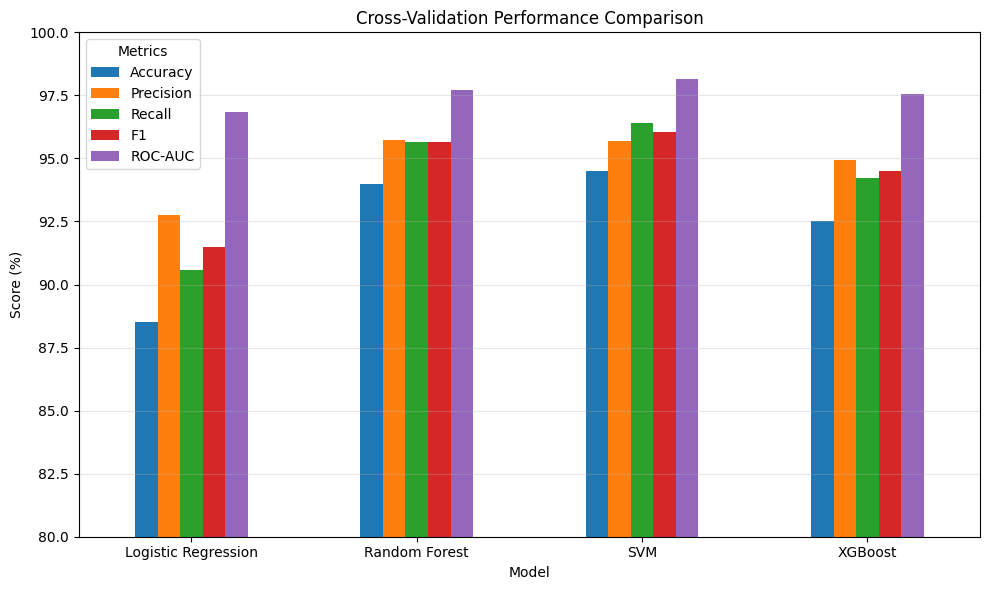

In [49]:
import matplotlib.pyplot as plt

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC"
]

ax = final_model_comparison_percentage[metrics].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Cross-Validation Performance Comparison")
plt.ylabel("Score (%)")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.ylim(80, 100)
plt.legend(title="Metrics")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [52]:
import joblib

joblib.dump(best_svm, "final_svm_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [53]:
cv_results_final = final_model_comparison_percentage.copy()

cv_results_final.to_csv(
    "model_comparison_cv.csv"
)

print("CV comparison saved successfully!")

CV comparison saved successfully!


In [54]:
final_test_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC",
        "PR-AUC"
    ],
    "SVM": [
        accuracy_score(y_test, y_test_pred),
        precision_score(y_test, y_test_pred, pos_label="Positive"),
        recall_score(y_test, y_test_pred, pos_label="Positive"),
        f1_score(y_test, y_test_pred, pos_label="Positive"),
        roc_auc_score(y_test_binary, y_test_proba),
        pr_auc
    ]
})

final_test_results["SVM"] = (
    final_test_results["SVM"] * 100
).round(2)

print(final_test_results)

      Metric    SVM
0   Accuracy  92.16
1  Precision  96.97
2     Recall  91.43
3   F1-score  94.12
4    ROC-AUC  96.61
5     PR-AUC  98.68


In [55]:
final_test_results.to_csv(
    "final_svm_test_results.csv",
    index=False
)

print("Final test results saved successfully!")

Final test results saved successfully!


In [56]:
from google.colab import files

files.download("final_svm_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [57]:
files.download("model_comparison_cv.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [58]:
files.download("final_svm_test_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>